<a href="https://colab.research.google.com/github/udamarla1/ML-_Login_Anomaly_-IsolationForest/blob/main/ML__Login_Anomaly__IsolationForest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Raw login events [only two days of data is available]->
1000000 records in the original notebook
##Data preprocessing & EDA ->
Missing values, timestamps, data types
##Daily aggregation ->
One record per user per day
##User behavioral baseline ->
Understand each user's normal behavior
##Deviation feature engineering ->
How different is today's activity from normal?
##Train Isolation Forest ->
Unsupervised machine learning
##Anomaly scoring and ranking ->
Identify the most unusual user-days
##Evaluation using actual UnAuth labels ->
Measure whether anomalies correspond to security incidents
##Explainable security alerts ->
Explain why activity is suspicious

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
from google.colab import drive
import os

drive.mount(os.path.join(os.getcwd(), 'drive'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
df = pd.read_csv("/content/drive/MyDrive/dataset/rba_small.csv")
df.head(10)

,index,Login Timestamp,User ID,Round-Trip Time [ms],IP Address,Country,Region,City,ASN,User Agent String,Browser Name and Version,OS Name and Version,Device Type,Login Successful,Is Attack IP,Is Account Takeover
0,0,2020-02-03 12:43:30.772,-4324475583306591935,NaN,10.0.65.171,NO,-,-,29695,Mozilla/5.0 (iPhone; CPU iPhone OS 13_4 like ...,Firefox 20.0.0.1618,iOS 13.4,mobile,False,False,False
1,1,2020-02-03 12:43:43.549,-4324475583306591935,NaN,194.87.207.6,AU,-,-,60117,Mozilla/5.0 (Linux; Android 4.1; Galaxy Nexus...,Chrome Mobile 46.0.2490,Android 4.1,mobile,False,False,False
2,2,2020-02-03 12:43:55.873,-3284137479262433373,NaN,81.167.144.58,NO,Vestland,Urangsvag,29695,Mozilla/5.0 (iPad; CPU OS 7_1 like Mac OS X) ...,Android 2.3.3.2672,iOS 7.1,mobile,True,False,False
3,3,2020-02-03 12:43:56.180,-4324475583306591935,NaN,170.39.78.152,US,-,-,393398,Mozilla/5.0 (Linux; Android 4.1; Galaxy Nexus...,Chrome Mobile WebView 85.0.4183,Android 4.1,mobile,False,False,False
4,4,2020-02-03 12:43:59.396,-4618854071942621186,NaN,10.0.0.47,US,Virginia,Ashburn,398986,Mozilla/5.0 (Linux; U; Android 2.2) Build/NMA...,Chrome Mobile WebView 85.0.4183,Android 2.2,mobile,False,True,False
5,5,2020-02-03 12:44:05.160,-4324475583306591935,NaN,209.236.123.126,US,-,-,393398,Mozilla/5.0 (Linux; Android 4.1; Galaxy Nexus...,Chrome Mobile WebView 85.0.4183,Android 4.1,mobile,False,True,False
6,6,2020-02-03 12:44:07.893,7246533443898239661,NaN,80.202.228.214,NO,-,-,15659,Mozilla/5.066704189 Mozilla/5.0 (X11; CrOS x8...,Chrome 69.0.3497.17.19,Chrome OS 13020.67.3,desktop,True,False,False
7,7,2020-02-03 12:44:12.799,-3243978724802435038,NaN,170.39.78.177,US,-,-,393398,Mozilla/5.0 (Linux; Android 10.0.99; H30-U10) ...,Chrome Mobile 81.0.4044.1931,Android 10.0.99,mobile,False,False,False
8,8,2020-02-03 12:44:17.474,8076000552587369902,NaN,10.0.61.212,NO,-,-,29695,Mozilla/5.0 (Linux; U; Android 7.1.2; en-gb; R...,MiuiBrowser 12.6.5,Android 7.1.2,mobile,False,False,False
9,9,2020-02-03 12:44:19.071,-3065936140549856249,NaN,92.221.109.162,NO,Rogaland,Sandnes,29695,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_14_6...,Chrome 69.0.3497.17.28,Mac OS X 10.14.6,desktop,True,False,False


In [13]:
df.columns

Index(['index', 'Login Timestamp', 'User ID', 'Round-Trip Time [ms]',
       'IP Address', 'Country', 'Region', 'City', 'ASN', 'User Agent String',
       'Browser Name and Version', 'OS Name and Version', 'Device Type',
       'Login Successful', 'Is Attack IP', 'Is Account Takeover'],
      dtype='object')

In [16]:
df.shape

(100000, 16)

In [14]:
df.dtypes

,0
index,int64
Login Timestamp,object
User ID,int64
Round-Trip Time [ms],float64
IP Address,object
Country,object
Region,object
City,object
ASN,int64
User Agent String,object


In [15]:
df.isnull().sum()

,0
index,0
Login Timestamp,0
User ID,0
Round-Trip Time [ms],95718
IP Address,0
Country,0
Region,78
City,35
ASN,0
User Agent String,0


In [17]:
df['User ID'].nunique()

41500

In [18]:
df["User ID"].value_counts().head(10)

,count
User ID,
-4324475583306591935,35411
-7095173164571071135,59
-5239294135691841703,58
-1527109053794272566,53
-4351595584410823177,43
-4771330981959858007,37
1311662966004919813,37
8145562822160797599,36
6633007929620951525,34


In [20]:
df["User ID"].mean()
df["User ID"].std()

4.749510426813621e+18

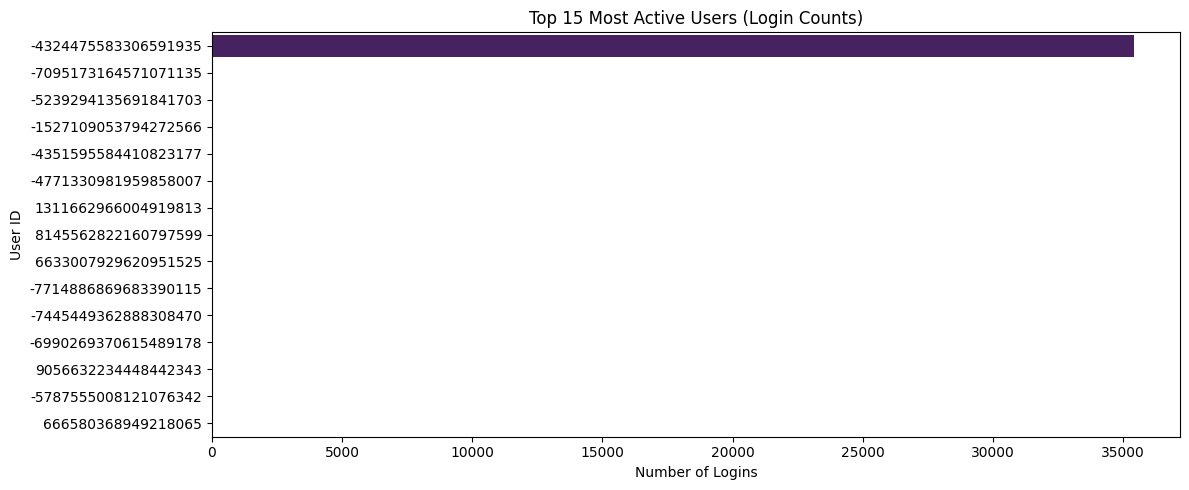

In [23]:
# Get the top 15 most active users
top_users = df['User ID'].value_counts().head(15)

# Plot the top 15 most active users
plt.figure(figsize=(12, 5))
sns.barplot(
    x=top_users.values,
    y=top_users.index.astype(str),
    hue=top_users.index.astype(str),
    palette='viridis',
    legend=False
)
plt.title('Top 15 Most Active Users (Login Counts)')
plt.xlabel('Number of Logins')
plt.ylabel('User ID')
plt.tight_layout()
plt.show()

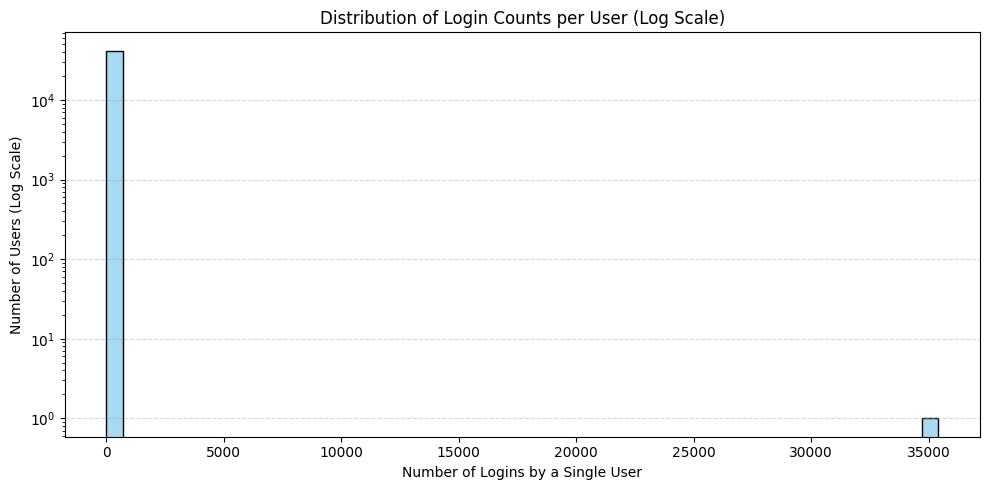

In [22]:
# Plot the overall distribution of login counts per user
user_counts = df['User ID'].value_counts()

plt.figure(figsize=(10, 5))
sns.histplot(user_counts, bins=50, kde=False, color='skyblue')
plt.yscale('log') # Using log scale due to the heavy skew
plt.title('Distribution of Login Counts per User (Log Scale)')
plt.xlabel('Number of Logins by a Single User')
plt.ylabel('Number of Users (Log Scale)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

,Login Range,Number of Users,Percentage of Total
0,1 login,29900,72.05
1,2 logins,6884,16.59
2,3-5 logins,3924,9.46
3,6-10 logins,631,1.52
4,11-50 logins,157,0.38
5,51-100 logins,3,0.01
6,100+ logins,1,0.00


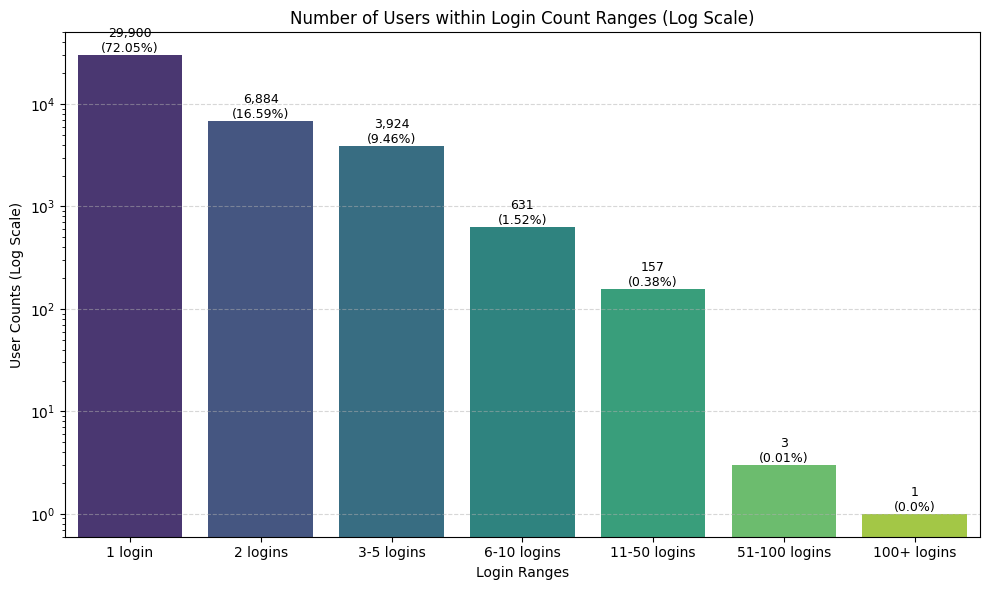

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define the bins and labels for login counts
bins = [0, 1, 2, 5, 10, 50, 100, float('inf')]
labels = ['1 login', '2 logins', '3-5 logins', '6-10 logins', '11-50 logins', '51-100 logins', '100+ logins']

# Cut the user counts into the specified ranges
user_ranges = pd.cut(user_counts, bins=bins, labels=labels)
range_distribution = user_ranges.value_counts().reindex(labels)

# Display the structured counts
dist_df = pd.DataFrame({
    'Login Range': range_distribution.index,
    'Number of Users': range_distribution.values,
    'Percentage of Total': (range_distribution.values / len(user_counts) * 100).round(2)
})
display(dist_df)

# Visualize the user segment distribution
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Login Range',
    y='Number of Users',
    data=dist_df,
    hue='Login Range',
    palette='viridis',
    legend=False
)
plt.yscale('log')
plt.title('Number of Users within Login Count Ranges (Log Scale)')
plt.xlabel('Login Ranges')
plt.ylabel('User Counts (Log Scale)')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add exact count values on top of each bar
for index, row in dist_df.iterrows():
    plt.text(index, row['Number of Users'], f"{row['Number of Users']:,}\n({row['Percentage of Total']}%)",
             color='black', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## Time - Series Feature Extraction

In [25]:

df["Login Timestamp"] = pd.to_datetime(
    df["Login Timestamp"],
    utc=True
)

df["date"] = df["Login Timestamp"].dt.date
df["hour"] = df["Login Timestamp"].dt.hour
df["is_night"] = df["hour"].between(0, 5)

In [26]:
import pandas as pd

# Aggregate login events per user per day
daily_agg = df.groupby(['User ID', 'date']).agg(
    total_logins=('index', 'count'),
    successful_logins=('Login Successful', 'sum'),
    failed_logins=('Login Successful', lambda x: (x == False).sum()),
    attack_ip_logins=('Is Attack IP', 'sum'),
    account_takeovers=('Is Account Takeover', 'sum'),
    night_logins=('is_night', 'sum')
).reset_index()

# Show the aggregated daily dataset summary
print(f"Aggregated dataset shape: {daily_agg.shape}")
display(daily_agg.head(10))

Aggregated dataset shape: (43124, 8)


,User ID,date,total_logins,successful_logins,failed_logins,attack_ip_logins,account_takeovers,night_logins
0,-9222772478737808777,2020-02-03,1,1,0,0,0,0
1,-9222021806417972337,2020-02-04,1,0,1,0,0,0
2,-9221337715387154957,2020-02-04,3,3,0,0,0,0
3,-9220078102273280830,2020-02-04,2,2,0,0,0,0
4,-9219046449471242030,2020-02-04,1,1,0,0,0,0
5,-9218796572594384652,2020-02-04,1,1,0,0,0,0
6,-9218540273981090185,2020-02-03,1,1,0,0,0,0
7,-9218199126639810598,2020-02-03,2,2,0,0,0,0
8,-9218199126639810598,2020-02-04,1,1,0,0,0,0
9,-9217553619747729063,2020-02-04,1,1,0,0,0,0


In [27]:
# Calculate each user's behavioral baseline (mean and standard deviation of active days)
user_baseline = daily_agg.groupby('User ID').agg(
    mean_logins=('total_logins', 'mean'),
    std_logins=('total_logins', 'std'),
    mean_failures=('failed_logins', 'mean'),
    std_failures=('failed_logins', 'std'),
    mean_night_logins=('night_logins', 'mean'),
    std_night_logins=('night_logins', 'std'),
    total_active_days=('date', 'nunique')
).reset_index()

# Standard deviation is NaN for users with only 1 active day; we'll fill those with 0
user_baseline.fillna(0, inplace=True)

# Display summary of user baseline dataset
print(f"User Baseline shape: {user_baseline.shape}")
display(user_baseline.head(10))

User Baseline shape: (41500, 8)


,User ID,mean_logins,std_logins,mean_failures,std_failures,mean_night_logins,std_night_logins,total_active_days
0,-9222772478737808777,1.0,0.000000,0.0,0.0,0.0,0.0,1
1,-9222021806417972337,1.0,0.000000,1.0,0.0,0.0,0.0,1
2,-9221337715387154957,3.0,0.000000,0.0,0.0,0.0,0.0,1
3,-9220078102273280830,2.0,0.000000,0.0,0.0,0.0,0.0,1
4,-9219046449471242030,1.0,0.000000,0.0,0.0,0.0,0.0,1
5,-9218796572594384652,1.0,0.000000,0.0,0.0,0.0,0.0,1
6,-9218540273981090185,1.0,0.000000,0.0,0.0,0.0,0.0,1
7,-9218199126639810598,1.5,0.707107,0.0,0.0,0.0,0.0,2
8,-9217553619747729063,1.0,0.000000,0.0,0.0,0.0,0.0,1
9,-9217525792102926186,1.0,0.000000,0.0,0.0,1.0,0.0,1


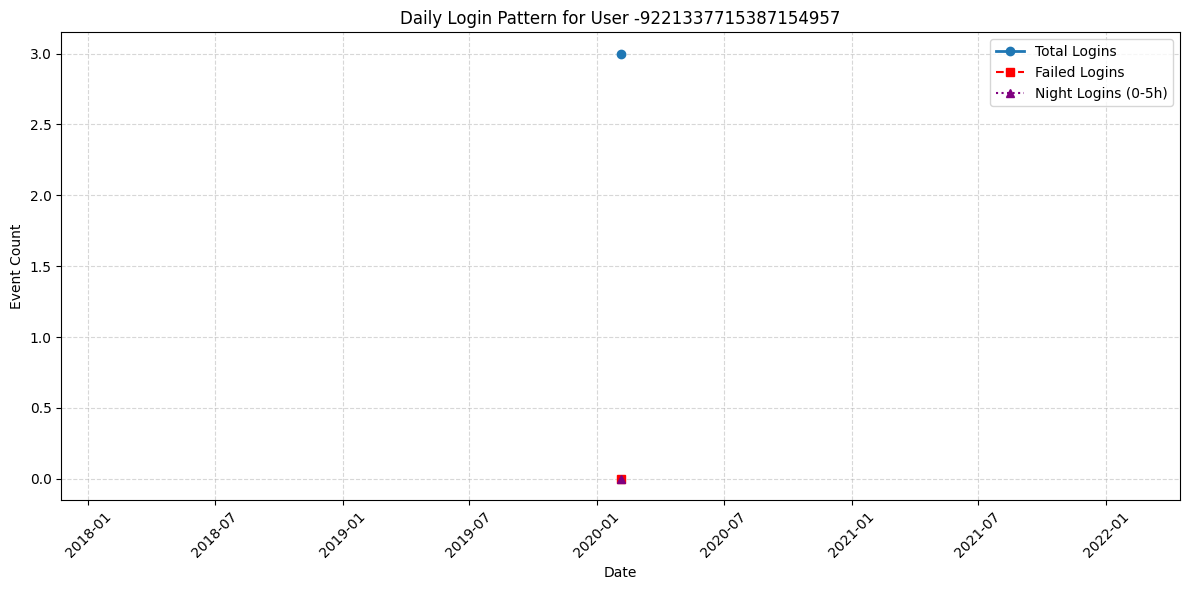

In [33]:
# Select the most active user
target_user = -9221337715387154957
user_data = daily_agg[daily_agg['User ID'] == target_user].sort_values('date')

# Plot daily metrics over time for this user
plt.figure(figsize=(12, 6))
plt.plot(user_data['date'], user_data['total_logins'], marker='o', label='Total Logins', linewidth=2)
plt.plot(user_data['date'], user_data['failed_logins'], marker='s', label='Failed Logins', color='red', linestyle='--')
plt.plot(user_data['date'], user_data['night_logins'], marker='^', label='Night Logins (0-5h)', color='purple', linestyle=':')

plt.title(f'Daily Login Pattern for User {target_user}')
plt.xlabel('Date')
plt.ylabel('Event Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [34]:
import pandas as pd
import numpy as np

# Merge daily aggregation with the user baseline statistics
features_df = pd.merge(daily_agg, user_baseline, on='User ID', how='left')

# Compute deviation (Z-score style) features
# Avoid division by zero by using np.where to fall back to absolute differences or 0 when std is 0
features_df['dev_logins'] = np.where(
    features_df['std_logins'] > 0,
    (features_df['total_logins'] - features_df['mean_logins']) / features_df['std_logins'],
    features_df['total_logins'] - features_df['mean_logins']
)

features_df['dev_failures'] = np.where(
    features_df['std_failures'] > 0,
    (features_df['failed_logins'] - features_df['mean_failures']) / features_df['std_failures'],
    features_df['failed_logins'] - features_df['mean_failures']
)

features_df['dev_night_logins'] = np.where(
    features_df['std_night_logins'] > 0,
    (features_df['night_logins'] - features_df['mean_night_logins']) / features_df['std_night_logins'],
    features_df['night_logins'] - features_df['mean_night_logins']
)

# Keep track of absolute increases as well
features_df['abs_login_increase'] = features_df['total_logins'] - features_df['mean_logins']
features_df['abs_failure_increase'] = features_df['failed_logins'] - features_df['mean_failures']

# Display the top dev_logins to see our engineered features in action
print(f"Feature Engineering completed. Final dataset shape: {features_df.shape}")
display(features_df.sort_values(by='dev_logins', ascending=False).head(10))

Feature Engineering completed. Final dataset shape: (43124, 20)


,User ID,date,total_logins,successful_logins,failed_logins,attack_ip_logins,account_takeovers,night_logins,mean_logins,std_logins,mean_failures,std_failures,mean_night_logins,std_night_logins,total_active_days,dev_logins,dev_failures,dev_night_logins,abs_login_increase,abs_failure_increase
13201,-3649665297783472532,2020-02-04,4,4,0,0,0,1,2.5,2.121320,0.0,0.000000,0.5,0.707107,2,0.707107,0.000000,0.707107,1.5,0.0
20135,-679368425517599849,2020-02-03,7,7,0,0,0,0,4.0,4.242641,0.0,0.000000,0.0,0.000000,2,0.707107,0.000000,0.000000,3.0,0.0
36248,6277760011701919217,2020-02-03,8,0,8,0,0,0,4.5,4.949747,4.0,5.656854,0.0,0.000000,2,0.707107,0.707107,0.000000,3.5,4.0
19161,-1093565244842999728,2020-02-04,4,4,0,0,0,0,2.5,2.121320,0.5,0.707107,0.0,0.000000,2,0.707107,-0.707107,0.000000,1.5,-0.5
37371,6757249688885310616,2020-02-03,5,5,0,0,0,0,3.5,2.121320,0.5,0.707107,0.0,0.000000,2,0.707107,-0.707107,0.000000,1.5,-0.5
35563,5983368948090577015,2020-02-03,5,3,2,0,0,0,3.5,2.121320,1.5,0.707107,0.0,0.000000,2,0.707107,0.707107,0.000000,1.5,0.5
33408,5044171602914499993,2020-02-04,11,8,3,0,0,0,8.0,4.242641,2.5,0.707107,0.0,0.000000,2,0.707107,0.707107,0.000000,3.0,0.5
18395,-1431123440027499996,2020-02-04,4,3,1,0,0,0,2.5,2.121320,0.5,0.707107,0.0,0.000000,2,0.707107,0.707107,0.000000,1.5,0.5
37470,6801044832990414040,2020-02-03,7,7,0,0,0,0,4.0,4.242641,0.0,0.000000,0.5,0.707107,2,0.707107,0.000000,-0.707107,3.0,0.0
2286,-8244673117257249604,2020-02-03,10,6,4,0,0,0,5.5,6.363961,2.0,2.828427,0.0,0.000000,2,0.707107,0.707107,0.000000,4.5,2.0


In [30]:
from sklearn.ensemble import IsolationForest

# Define the features we want our Isolation Forest model to use
feature_cols = [
    'dev_logins',
    'dev_failures',
    'dev_night_logins',
    'abs_login_increase',
    'abs_failure_increase'
]

X = features_df[feature_cols]

# Initialize the Isolation Forest
# contamination='auto' lets the model decide threshold, or we can look at decision function scores
iso_forest = IsolationForest(n_estimators=100, contamination=0.01, random_state=42)

# Fit the model and predict anomaly labels
# -1 indicates anomaly, 1 indicates normal
features_df['anomaly_label'] = iso_forest.fit_predict(X)

# Save the raw anomaly scores (lower/more negative means more anomalous)
features_df['anomaly_score'] = iso_forest.decision_function(X)

# Display summary counts of anomalies detected
anomaly_counts = features_df['anomaly_label'].value_counts()
print(f"Isolation Forest training completed!")
print(f"Normal days detected (1): {anomaly_counts.get(1, 0)}")
print(f"Anomalous days detected (-1): {anomaly_counts.get(-1, 0)}")

Isolation Forest training completed!
Normal days detected (1): 42704
Anomalous days detected (-1): 420


In [31]:
# Sort the anomalies to find the most extreme cases
anomalies = features_df[features_df['anomaly_label'] == -1].sort_values(by='anomaly_score')

# Calculate how many of the flagged anomalies correspond to known attacks or takeovers
total_anomalies_flagged = len(anomalies)
flagged_with_ato = (anomalies['account_takeovers'] > 0).sum()
flagged_with_attack_ip = (anomalies['attack_ip_logins'] > 0).sum()
flagged_with_either = ((anomalies['account_takeovers'] > 0) | (anomalies['attack_ip_logins'] > 0)).sum()

print("=== Anomaly Validation Summary ===")
print(f"Total Anomalies Flagged by Model: {total_anomalies_flagged}")
print(f"Anomalies with confirmed Account Takeover (ATO) flags: {flagged_with_ato} ({flagged_with_ato/total_anomalies_flagged*100:.2f}%)")
print(f"Anomalies with confirmed Attack IPs: {flagged_with_attack_ip} ({flagged_with_attack_ip/total_anomalies_flagged*100:.2f}%)")
print(f"Anomalies with either security flag: {flagged_with_either} ({flagged_with_either/total_anomalies_flagged*100:.2f}%)")
print("\n--- Top 10 Most Anomalous User-Days ---")
cols_to_show = ['User ID', 'date', 'total_logins', 'failed_logins', 'account_takeovers', 'attack_ip_logins', 'anomaly_score']
display(anomalies[cols_to_show].head(10))

=== Anomaly Validation Summary ===
Total Anomalies Flagged by Model: 420
Anomalies with confirmed Account Takeover (ATO) flags: 0 (0.00%)
Anomalies with confirmed Attack IPs: 51 (12.14%)
Anomalies with either security flag: 51 (12.14%)

--- Top 10 Most Anomalous User-Days ---


,User ID,date,total_logins,failed_logins,account_takeovers,attack_ip_logins,anomaly_score
5274,-6938178267032218003,2020-02-04,12,2,0,0,-0.064711
15446,-2679138127257105874,2020-02-04,7,0,0,3,-0.064146
4938,-7095173164571071135,2020-02-04,48,10,0,0,-0.062935
3441,-7744900319555866595,2020-02-04,13,13,0,5,-0.062935
11590,-4324475583306591935,2020-02-04,20823,20823,0,2982,-0.062935
40544,8145562822160797599,2020-02-03,22,9,0,22,-0.060567
42817,9085246441372114724,2020-02-03,10,4,0,0,-0.059444
40024,7925866163359329657,2020-02-03,9,4,0,0,-0.059444
11589,-4324475583306591935,2020-02-03,14588,14588,0,1640,-0.058322
4937,-7095173164571071135,2020-02-03,11,1,0,0,-0.058322


In [32]:
def generate_security_alert_text(row):
    reasons = []
    if row['total_logins'] > row['mean_logins'] + 3 * row['std_logins']:
        reasons.append(f"Login volume spiked (Today: {row['total_logins']}, Baseline Mean: {row['mean_logins']:.1f})")
    if row['failed_logins'] > row['mean_failures'] + 3 * row['std_failures']:
        reasons.append(f"Failed logins spiked abnormally (Today: {row['failed_logins']}, Baseline Mean: {row['mean_failures']:.1f})")
    if row['night_logins'] > row['mean_night_logins'] + 3 * row['std_night_logins'] and row['night_logins'] > 0:
        reasons.append(f"Suspicious night activity (Today: {row['night_logins']} night attempts, Baseline Mean: {row['mean_night_logins']:.1f})")

    # Fallback to absolute spikes if variance was too low to calculate standard deviation
    if not reasons:
        if row['abs_login_increase'] > 5:
            reasons.append(f"High absolute login increase (+{row['abs_login_increase']:.0f} logins over baseline)")
        if row['abs_failure_increase'] > 3:
            reasons.append(f"High absolute failure increase (+{row['abs_failure_increase']:.0f} failed attempts)")

    if not reasons:
        reasons.append("Multi-feature statistical deviation from typical login baseline")

    return " | ".join(reasons)

# Filter to top anomalies and generate explanations
top_alerts = anomalies.head(10).copy()
top_alerts['Alert Explanation'] = top_alerts.apply(generate_security_alert_text, axis=1)

# Display the final security dashboard
print("=== SECURITY ALERTS GENERATION ENGINE ===")
for idx, alert in top_alerts.iterrows():
    print(f"\n[ALERT] User ID: {alert['User ID']} | Date: {alert['date']} | Anomaly Score: {alert['anomaly_score']:.4f}")
    print(f"        Logins: {alert['total_logins']} | Failed: {alert['failed_logins']} | Night: {alert['night_logins']}")
    print(f"        Reason: {alert['Alert Explanation']}")

=== SECURITY ALERTS GENERATION ENGINE ===

[ALERT] User ID: -6938178267032218003 | Date: 2020-02-04 | Anomaly Score: -0.0647
        Logins: 12 | Failed: 2 | Night: 1
        Reason: Multi-feature statistical deviation from typical login baseline

[ALERT] User ID: -2679138127257105874 | Date: 2020-02-04 | Anomaly Score: -0.0641
        Logins: 7 | Failed: 0 | Night: 3
        Reason: Multi-feature statistical deviation from typical login baseline

[ALERT] User ID: -7095173164571071135 | Date: 2020-02-04 | Anomaly Score: -0.0629
        Logins: 48 | Failed: 10 | Night: 19
        Reason: High absolute login increase (+18 logins over baseline) | High absolute failure increase (+4 failed attempts)

[ALERT] User ID: -7744900319555866595 | Date: 2020-02-04 | Anomaly Score: -0.0629
        Logins: 13 | Failed: 13 | Night: 5
        Reason: High absolute failure increase (+5 failed attempts)

[ALERT] User ID: -4324475583306591935 | Date: 2020-02-04 | Anomaly Score: -0.0629
        Logins: 208

### Train-Test Splitting & Feature Scaling
We will split our dataset chronologically or randomly. Given that our dataset only spans two main days (2020-02-03 and 2020-02-04), a random train-test split (e.g., 80/20) will give us stable subsets of user behaviors. We will then fit our standard scaler only on the training partition to prevent data leakage, and apply it to both partitions.

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Define target variables to help evaluate the splits later
target_cols = ['Is Attack IP', 'Is Account Takeover']

# Perform an 80/20 train-test split on our daily aggregated features
train_df, test_df = train_test_split(features_df, test_size=0.20, random_state=42)

# Initialize and fit the standard scaler on the training features only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(train_df[feature_cols])
X_test_scaled = scaler.transform(test_df[feature_cols])

print(f"Train set shape: {X_train_scaled.shape}")
print(f"Test set shape: {X_test_scaled.shape}")

Train set shape: (34499, 5)
Test set shape: (8625, 5)


### Train & Evaluate Isolation Forest on Scaled Data
Now, we train the Isolation Forest model using the scaled training features, and predict anomalies on the test set.

In [38]:
# Retrain Isolation Forest on scaled training data
iso_forest_scaled = IsolationForest(n_estimators=100, contamination=0.01, random_state=42)
iso_forest_scaled.fit(X_train_scaled)

# Predict anomalies on both train and test sets (-1 = anomaly, 1 = normal)
train_df['anomaly_label_scaled'] = iso_forest_scaled.predict(X_train_scaled)
test_df['anomaly_label_scaled'] = iso_forest_scaled.predict(X_test_scaled)

# Store scores (decision function values)
train_df['anomaly_score_scaled'] = iso_forest_scaled.decision_function(X_train_scaled)
test_df['anomaly_score_scaled'] = iso_forest_scaled.decision_function(X_test_scaled)

print("=== Model Results on Test Set (Scaled) ===")
test_counts = test_df['anomaly_label_scaled'].value_counts()
print(f"Normal user-days: {test_counts.get(1, 0)}")
print(f"Anomalous user-days: {test_counts.get(-1, 0)}")

=== Model Results on Test Set (Scaled) ===
Normal user-days: 8547
Anomalous user-days: 78


In [37]:
# Evaluate how well the scaled test predictions overlap with confirmed attack labels
test_anomalies = test_df[test_df['anomaly_label_scaled'] == -1]
total_test_anomalies = len(test_anomalies)

flagged_attack_ips_test = (test_anomalies['attack_ip_logins'] > 0).sum()

print("=== Test Set Validation Summary ===")
print(f"Total Test Anomalies Flagged: {total_test_anomalies}")
print(f"Anomalies with confirmed Attack IPs: {flagged_attack_ips_test} ({flagged_attack_ips_test/max(1, total_test_anomalies)*100:.2f}%)")

=== Test Set Validation Summary ===
Total Test Anomalies Flagged: 78
Anomalies with confirmed Attack IPs: 9 (11.54%)


### Visualizing Isolation Forest Anomalies (PCA 2D Projection)
Since our feature space is 5-dimensional, we can apply Principal Component Analysis (PCA) to project our test set onto 2 dimensions for visualization. We will color-code the points to clearly distinguish between normal and anomalous activities.

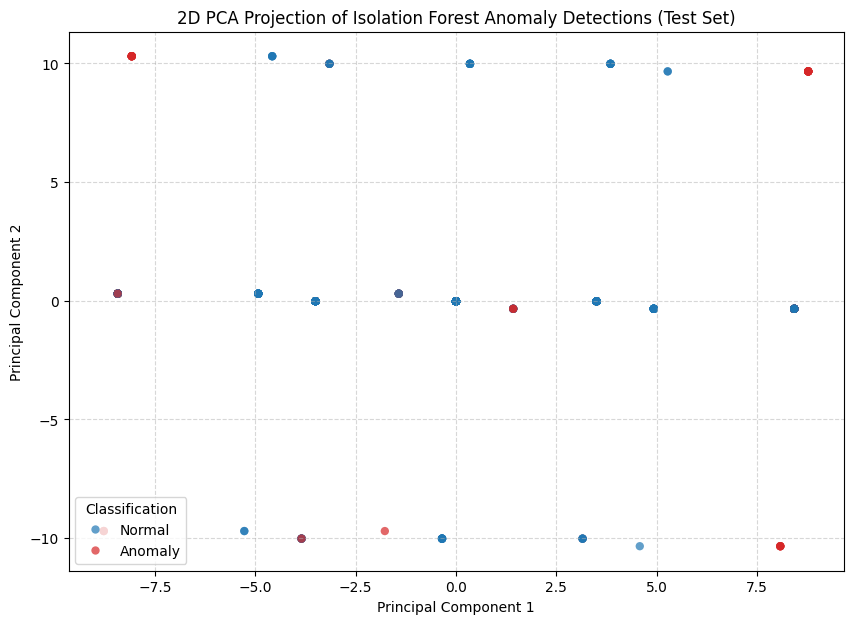

In [39]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Apply PCA to reduce the scaled test features to 2 dimensions
pca = PCA(n_components=2, random_state=42)
X_test_pca = pca.fit_transform(X_test_scaled)

# Create a temporary DataFrame for plotting
plot_df = pd.DataFrame(X_test_pca, columns=['PCA Dimension 1', 'PCA Dimension 2'])
plot_df['Is Anomaly'] = test_df['anomaly_label_scaled'].replace({1: 'Normal', -1: 'Anomaly'}).values

# Plot the data points
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='PCA Dimension 1',
    y='PCA Dimension 2',
    hue='Is Anomaly',
    data=plot_df,
    palette={'Normal': '#1f77b4', 'Anomaly': '#d62728'},
    alpha=0.7,
    edgecolor='none'
)

plt.title('2D PCA Projection of Isolation Forest Anomaly Detections (Test Set)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Classification')
plt.show()

### Calculate Baseline Takeover Rate
We will compute the average percentage of logins flagged as true Account Takeover instances (`Is Account Takeover`) to determine the base rate of security incidents in the dataset.

In [40]:
# Calculate baseline unAuthto (Account Takeover) rate across the full raw dataset
baseline_unAuthto_rate = df['Is Account Takeover'].mean()

print(f"Baseline Account Takeover Rate: {baseline_unAuthto_rate:.6f} ({baseline_unAuthto_rate * 100:.4f}%)")

Baseline Account Takeover Rate: 0.000020 (0.0020%)


### Comprehensive Model Evaluation with Classification Metrics
We will evaluate the performance of our Isolation Forest anomaly detector using standard classification metrics (Accuracy, Precision, Recall, F1-Score, ROC-AUC, and Average Precision) by comparing model detections to verified threat labels in the test partition.

In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# 1. Define Ground Truth: 1 if the day had any attack IP logins or account takeovers, else 0
y_true = ((test_df['attack_ip_logins'] > 0) | (test_df['account_takeovers'] > 0)).astype(int).values

# 2. Map Predictions: 1 if flagged as an anomaly (-1), 0 if normal (1)
y_pred = (test_df['anomaly_label_scaled'] == -1).astype(int).values

# 3. Continuous anomaly score: lower decision scores mean more anomalous, so we take the negative
y_score = -test_df['anomaly_score_scaled'].values

# Print requested metrics
print("Accuracy:", accuracy_score(y_true, y_pred))

print("Precision:", precision_score(
    y_true, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_true, y_pred, zero_division=0
))

print("F1 Score:", f1_score(
    y_true, y_pred, zero_division=0
))

print("ROC-AUC:", roc_auc_score(
    y_true, y_score
))

print("Average Precision:", average_precision_score(
    y_true, y_score
))

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Accuracy: 0.9152463768115942
Precision: 0.11538461538461539
Recall: 0.013412816691505217
F1 Score: 0.02403204272363151
ROC-AUC: 0.49643469697406883
Average Precision: 0.08046857710552682

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.99      0.96      7954
           1       0.12      0.01      0.02       671

    accuracy                           0.92      8625
   macro avg       0.52      0.50      0.49      8625
weighted avg       0.86      0.92      0.88      8625

Confusion Matrix:
[[7885   69]
 [ 662    9]]


### Feature Importance Analysis (Surrogate Model)
We will train a supervised Random Forest classifier using our 5 engineered features to predict verified threat incidents on our training set. This allows us to extract Gini-based feature importances and determine which specific metrics are most predictive of security incidents.

=== Feature Importance Ranking ===


,Feature,Importance
0,abs_login_increase,0.411394
1,abs_failure_increase,0.261158
2,dev_night_logins,0.177797
3,dev_failures,0.083412
4,dev_logins,0.066239


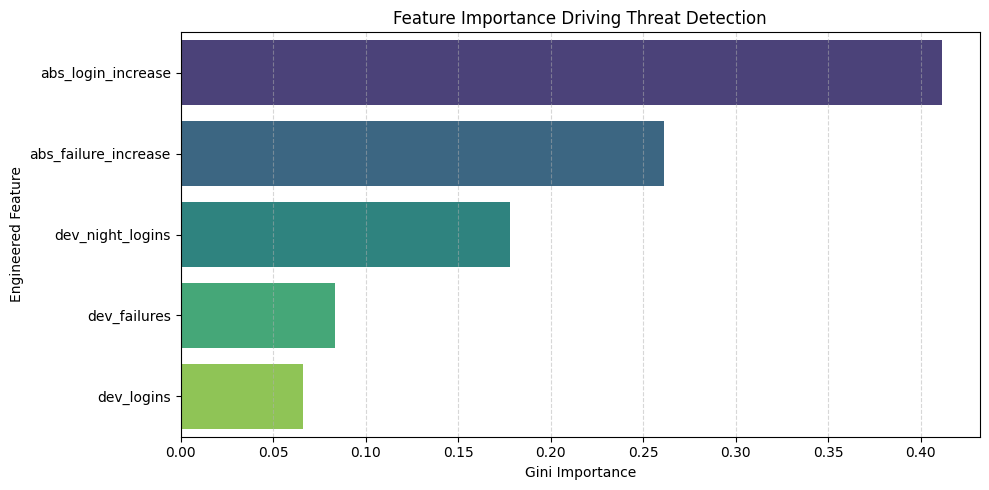

In [43]:
from sklearn.ensemble import RandomForestClassifier

# 1. Define the threat labels for the training set (Ground Truth)
y_train_true = ((train_df['attack_ip_logins'] > 0) | (train_df['account_takeovers'] > 0)).astype(int).values

# 2. Train a Random Forest classifier as our surrogate model
surrogate_rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
surrogate_rf.fit(X_train_scaled, y_train_true)

# 3. Extract and display feature importances
importances = surrogate_rf.feature_importances_
indices = np.argsort(importances)[::-1]

importance_df = pd.DataFrame({
    'Feature': [feature_cols[i] for i in indices],
    'Importance': importances[indices]
})

print("=== Feature Importance Ranking ===")
display(importance_df)

# 4. Plot Feature Importances
plt.figure(figsize=(10, 5))
sns.barplot(
    x='Importance',
    y='Feature',
    data=importance_df,
    hue='Feature',
    palette='viridis',
    legend=False
)
plt.title('Feature Importance Driving Threat Detection')
plt.xlabel('Gini Importance')
plt.ylabel('Engineered Feature')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Train a Supervised Random Forest Classifier
We will now build a fully supervised `RandomForestClassifier` targeting actual security incidents (`y_true`). We'll train the model on the scaled training partition and evaluate it on the test partition to measure how much our predictive scores (especially ROC-AUC and Recall) improve over the unsupervised model.

In [44]:
from sklearn.ensemble import RandomForestClassifier

# 1. Initialize and train the Supervised Random Forest Classifier
supervised_rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
supervised_rf.fit(X_train_scaled, y_train_true)

# 2. Predict on the test set
y_pred_rf = supervised_rf.predict(X_test_scaled)
y_prob_rf = supervised_rf.predict_proba(X_test_scaled)[:, 1]

# 3. Evaluate the model performance
print("=== Supervised Random Forest Test Metrics ===")
print("Accuracy:", accuracy_score(y_true, y_pred_rf))
print("Precision:", precision_score(y_true, y_pred_rf, zero_division=0))
print("Recall:", recall_score(y_true, y_pred_rf, zero_division=0))
print("F1 Score:", f1_score(y_true, y_pred_rf, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_true, y_prob_rf))
print("Average Precision:", average_precision_score(y_true, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_true, y_pred_rf, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred_rf))

=== Supervised Random Forest Test Metrics ===
Accuracy: 0.10585507246376812
Precision: 0.07843372051251347
Recall: 0.9761549925484352
F1 Score: 0.14520062070494347
ROC-AUC: 0.5046886587445621
Average Precision: 0.078545931900019

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.03      0.06      7954
           1       0.08      0.98      0.15       671

    accuracy                           0.11      8625
   macro avg       0.51      0.50      0.10      8625
weighted avg       0.87      0.11      0.07      8625

Confusion Matrix:
[[ 258 7696]
 [  16  655]]
